In [33]:

!pip install easyocr


In [34]:

import easyocr
from google.colab import files
from IPython.display import display, Image
from pathlib import Path


In [35]:

reader = easyocr.Reader(['en'], gpu=False)


Saving snta.png to snta (2).png
Image path: snta (2).png


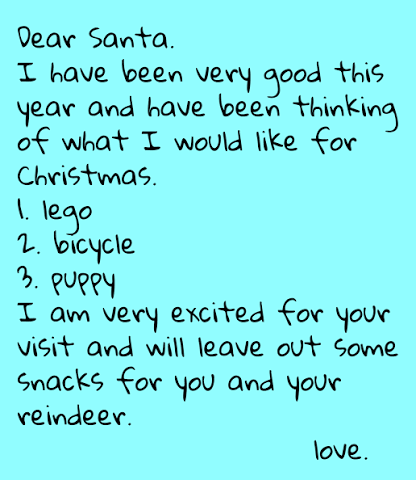

In [36]:

from google.colab import files
from IPython.display import display, Image

uploaded = files.upload()

image_path = next(iter(uploaded))

print("Image path:", image_path)
display(Image(filename=image_path))


In [37]:

results = reader.readtext(image_path)

print("OCR Results:\n")

for bbox, text, confidence in results:
    print(f"Text: {text}")
    print(f"Confidence: {confidence:.2%}")
    print("-" * 40)


OCR Results:

Text: Dear Santa:
Confidence: 58.29%
----------------------------------------
Text: I
Confidence: 99.83%
----------------------------------------
Text: have been very good this
Confidence: 82.29%
----------------------------------------
Text: year
Confidence: 68.02%
----------------------------------------
Text: and have been
Confidence: 71.07%
----------------------------------------
Text: of what
Confidence: 93.34%
----------------------------------------
Text: I woUld like for
Confidence: 48.56%
----------------------------------------
Text: Christmas.
Confidence: 83.65%
----------------------------------------
Text: lego
Confidence: 93.56%
----------------------------------------
Text: 2
Confidence: 98.85%
----------------------------------------
Text: bicycle
Confidence: 99.94%
----------------------------------------
Text: 3. puppy
Confidence: 46.15%
----------------------------------------
Text: I
Confidence: 99.83%
----------------------------------------
Text: am

In [38]:

texts = reader.readtext(image_path, detail=0)

extracted_text = "\n".join(texts)

print(extracted_text)


Dear Santa:
I
have been very good this
year
and have been
of what
I woUld like for
Christmas.
lego
2
bicycle
3. puppy
I
am very excited for YoUr
visit and
will leave out Gome
Snacks for You and yoUr
reindeer:
love_
thinking


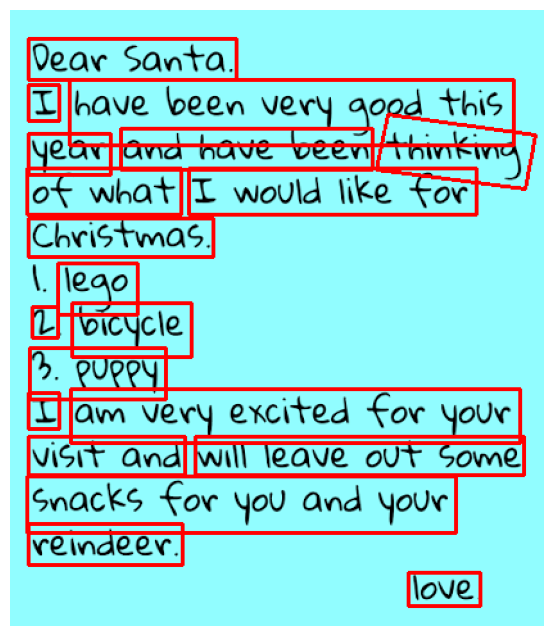

In [39]:

import cv2
import matplotlib.pyplot as plt

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for bbox, text, confidence in results:
    points = [(int(x), int(y)) for x, y in bbox]

    for i in range(4):
        cv2.line(
            image,
            points[i],
            points[(i + 1) % 4],
            (255, 0, 0),
            2
        )

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.axis("off")
plt.show()


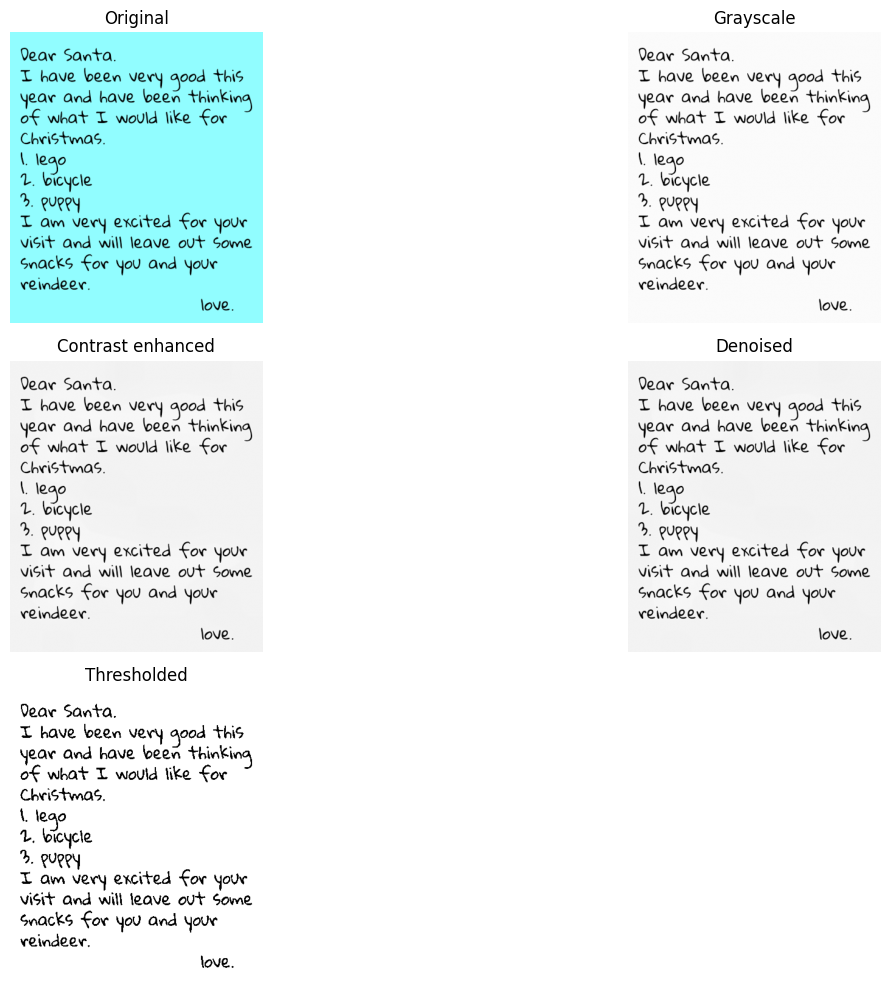

In [40]:

import cv2
import matplotlib.pyplot as plt

# Load the same image you already uploaded
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image not found. Check image_path.")

# Technique 1: Grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Technique 2: Contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
enhanced = clahe.apply(gray)

# Technique 3: Noise reduction
denoised = cv2.fastNlMeansDenoising(
    enhanced,
    None,
    h=10
)

# Technique 4: Adaptive thresholding
thresholded = cv2.adaptiveThreshold(
    denoised,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Save all versions for comparison
versions = {
    "Original": cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
    "Grayscale": gray,
    "Contrast enhanced": enhanced,
    "Denoised": denoised,
    "Thresholded": thresholded
}

# Display all versions
plt.figure(figsize=(14, 10))

for i, (name, img) in enumerate(versions.items(), 1):
    plt.subplot(3, 2, i)
    plt.imshow(
        img,
        cmap="gray" if len(img.shape) == 2 else None
    )
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [41]:

import time

ocr_results = {}

for name, img in versions.items():
    start = time.perf_counter()

    results = reader.readtext(img)

    elapsed = time.perf_counter() - start

    text = "\n".join(
        result[1] for result in results
    )

    confidence = (
        sum(result[2] for result in results) / len(results)
        if results else 0
    )

    ocr_results[name] = {
        "text": text,
        "confidence": confidence,
        "time": elapsed
    }

    print(f"\n{'=' * 40}")
    print(f"VERSION: {name}")
    print(f"{'=' * 40}")
    print("Extracted text:")
    print(text)
    print(f"Average confidence: {confidence:.4f}")
    print(f"Time taken: {elapsed:.3f} seconds")



VERSION: Original
Extracted text:
Dear Santa:
I
have been very good this
year
and have been
of what
I would like for
Christmas.
lego
2
bicycle
3. puppy
I
am very excited for YoUr
visit and
will leave out Gome
Snacks for You and YoUr
reindeer:
love_
thinking
Average confidence: 0.7864
Time taken: 2.393 seconds

VERSION: Grayscale
Extracted text:
Dear Santa:
I
have been very
good this
year And
have been
of what I WoUld Iike for
Christmas.
2
bicycle
3. puppy
I
am very excited for
visit and will leave out Gome
Snacks for You and yoUr
reindeer:
love_
thinking
Ieg?
YoUr
Average confidence: 0.7540
Time taken: 2.425 seconds

VERSION: Contrast enhanced
Extracted text:
Dear Santa:
I
have been very
good this
year and
have been
of what
I would like for
Christmas.
2
bicycle
3. puppy
I
am very excited for YoUr
visit and will leave out Gome
Snacks for You and yoUr
reindeer:
love_
thinking
Ieg?
Average confidence: 0.7653
Time taken: 2.528 seconds

VERSION: Denoised
Extracted text:
Dear Santa:
I
have 

In [42]:

def edit_distance(reference, hypothesis):
    # Levenshtein edit distance
    previous = list(range(len(hypothesis) + 1))

    for i, ref_char in enumerate(reference, 1):
        current = [i]

        for j, hyp_char in enumerate(hypothesis, 1):
            substitution = (
                previous[j - 1] + (ref_char != hyp_char)
            )
            deletion = previous[j] + 1
            insertion = current[j - 1] + 1

            current.append(
                min(substitution, deletion, insertion)
            )

        previous = current

    return previous[-1]


def calculate_cer(ground_truth, predicted_text):
    # Normalize line breaks and repeated whitespace
    reference = " ".join(ground_truth.split())
    hypothesis = " ".join(predicted_text.split())

    if len(reference) == 0:
        return 0.0 if len(hypothesis) == 0 else float("inf")

    return edit_distance(reference, hypothesis) / len(reference)


# Replace this example with the EXACT text in your image

ground_truth = """Dear Santa.
I have been very good this year and have been thinking of what I would like for Christmas.
1. lego
2. bicycle
3. Puppy
I am very excited for your visit and will leave out some Snacks for you and your reindeer.
love."""


print("CER comparison (lower is better):\n")

for name, result in ocr_results.items():
    cer = calculate_cer(
        ground_truth,
        result["text"]
    )

    print(f"{name:20} CER: {cer:.2%}")


CER comparison (lower is better):

Original             CER: 14.10%
Grayscale            CER: 23.35%
Contrast enhanced    CER: 18.06%
Denoised             CER: 18.06%
Thresholded          CER: 19.82%


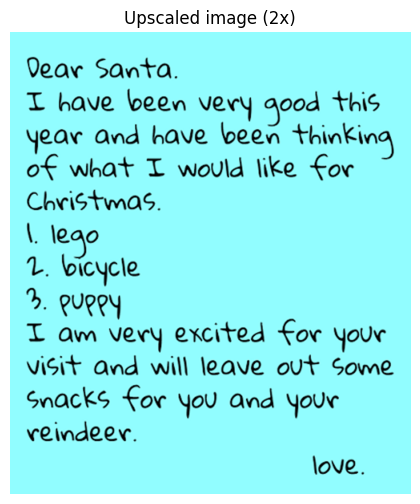

Upscaled OCR output:
Dear Santa:
I
have been very
this
and have been
of what I WoUld like for
Christmas.
L
lego
2 .
bicycle
2. puppy
I
am very excited for Your
visit and will leave out Gome
Snacks for You
YoUr
reindeer:
love _
good
thinking
year
And

Upscaled CER: 27.31%


In [43]:

height, width = image.shape[:2]

upscaled = cv2.resize(
    image,
    (width * 2, height * 2),
    interpolation=cv2.INTER_CUBIC
)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(upscaled, cv2.COLOR_BGR2RGB))
plt.title("Upscaled image (2x)")
plt.axis("off")
plt.show()

# Run the same EasyOCR model on the enlarged image
upscaled_results = reader.readtext(upscaled)

upscaled_text = "\n".join(
    result[1] for result in upscaled_results
)

print("Upscaled OCR output:")
print(upscaled_text)

print(
    "\nUpscaled CER:",
    f"{calculate_cer(ground_truth, upscaled_text):.2%}"
)


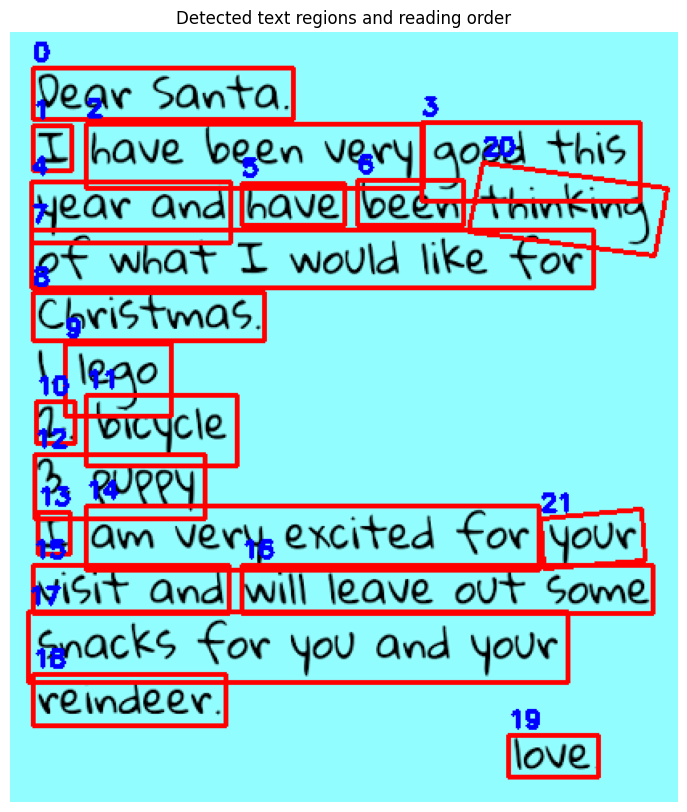

0 'Dear Santa:' 0.603
1 'I' 0.998
2 'have been very' 0.84
3 'good this' 0.724
4 'year And' 0.619
5 'have' 0.967
6 'been' 0.987
7 'of what I woUld like for' 0.597
8 'Christmas.' 0.865
9 'Iego' 0.783
10 '2,' 0.459
11 'bicycle' 0.998
12 '3. puppy' 0.433
13 'I' 0.994
14 'am very excited for' 0.983
15 'visit and' 0.777
16 'will leave out Gome' 0.782
17 'Snacks for YoU and YoUr' 0.632
18 'reindeer:' 0.654
19 'love_' 0.987
20 'thinking' 0.807
21 'YoUr' 0.665


In [44]:

import matplotlib.pyplot as plt
import cv2

# Run EasyOCR on the original image
results = reader.readtext(image)

# Draw every detected text region and its index
visual = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()

for i, (bbox, text, confidence) in enumerate(results):
    points = [
        tuple(map(int, point))
        for point in bbox
    ]

    points_np = __import__("numpy").array(points)

    cv2.polylines(
        visual,
        [points_np],
        True,
        (255, 0, 0),
        2
    )

    x, y = points[0]
    cv2.putText(
        visual,
        str(i),
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        2
    )

plt.figure(figsize=(14, 10))
plt.imshow(visual)
plt.title("Detected text regions and reading order")
plt.axis("off")
plt.show()

# Print detections in the order EasyOCR returned them
for i, (_, text, confidence) in enumerate(results):
    print(i, repr(text), round(confidence, 3))


In [46]:

# Group detected words into approximate text lines

# Estimate each box's vertical center and height
boxes = []

for bbox, text, confidence in results:
    xs = [p[0] for p in bbox]
    ys = [p[1] for p in bbox]

    boxes.append({
        "text": text,
        "x": min(xs),
        "y": min(ys),
        "center_y": (min(ys) + max(ys)) / 2,
        "height": max(ys) - min(ys)
    })

# Process boxes from top to bottom
boxes.sort(key=lambda b: b["center_y"])

lines = []

for box in boxes:
    matched_line = None

    for line in lines:
        # Compare against the current line's average vertical center
        line_center = sum(
            b["center_y"] for b in line
        ) / len(line)

        # Allow a tolerance based on text-box height
        tolerance = max(10, box["height"] * 0.6)

        if abs(box["center_y"] - line_center) < tolerance:
            matched_line = line
            break

    if matched_line is None:
        lines.append([box])
    else:
        matched_line.append(box)

# Sort words left to right inside each line
lines.sort(
    key=lambda line: min(b["y"] for b in line)
)

print("Reconstructed paragraph:\n")

for line in lines:
    line.sort(key=lambda b: b["x"])
    print(" ".join(b["text"] for b in line))


Reconstructed paragraph:

Dear Santa:
I have been very good this thinking
year And have been
of what I woUld like for
Christmas.
Iego
2, bicycle
3. puppy
I am very excited for YoUr
visit and will leave out Gome
Snacks for YoU and YoUr
reindeer:
love_


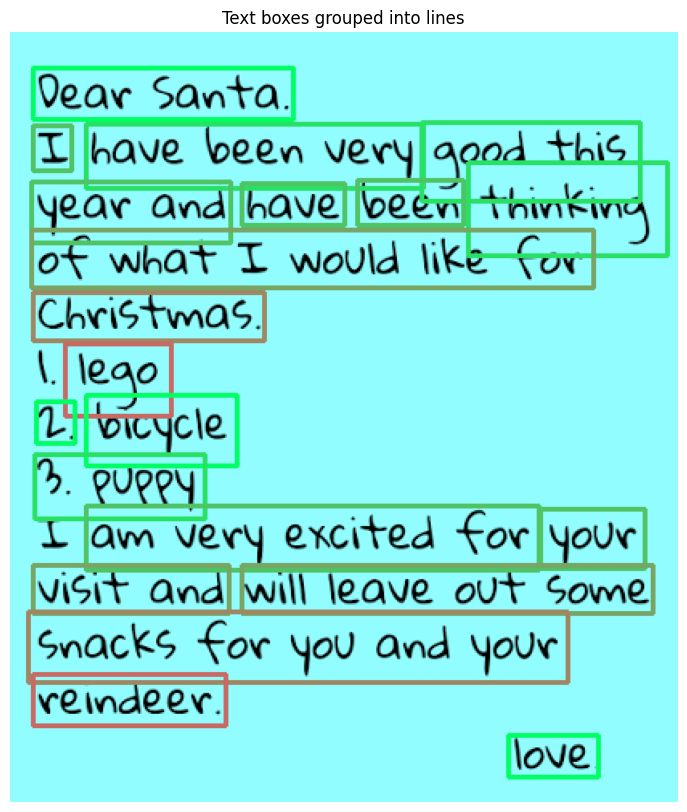

In [47]:

import matplotlib.pyplot as plt
import cv2

# Give each detected box a different color by assigned line
visual = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()

for line_id, line in enumerate(lines):
    for box in line:
        # Find the original bounding box for this detected text
        for bbox, text, confidence in results:
            if text == box["text"]:
                xs = [p[0] for p in bbox]
                ys = [p[1] for p in bbox]

                x1, y1 = int(min(xs)), int(min(ys))
                x2, y2 = int(max(xs)), int(max(ys))

                cv2.rectangle(
                    visual,
                    (x1, y1),
                    (x2, y2),
                    (40 * (line_id % 6), 255 - 30 * (line_id % 6), 100),
                    2
                )
                break

plt.figure(figsize=(14, 10))
plt.imshow(visual)
plt.title("Text boxes grouped into lines")
plt.axis("off")
plt.show()


In [48]:

# Improved line grouping using vertical overlap

boxes = []

for idx, (bbox, text, confidence) in enumerate(results):
    xs = [p[0] for p in bbox]
    ys = [p[1] for p in bbox]

    boxes.append({
        "idx": idx,
        "text": text,
        "x1": min(xs),
        "x2": max(xs),
        "y1": min(ys),
        "y2": max(ys),
        "height": max(ys) - min(ys)
    })

# Process boxes from top to bottom
boxes.sort(key=lambda b: (b["y1"], b["x1"]))

lines = []

for box in boxes:
    best_line = None
    best_overlap = 0

    for line in lines:
        line_top = min(b["y1"] for b in line)
        line_bottom = max(b["y2"] for b in line)

        overlap = max(
            0,
            min(box["y2"], line_bottom)
            - max(box["y1"], line_top)
        )

        smaller_height = max(
            1,
            min(box["height"], line_bottom - line_top)
        )

        overlap_ratio = overlap / smaller_height

        if overlap_ratio > best_overlap:
            best_overlap = overlap_ratio
            best_line = line

    # Require at least 50% vertical overlap
    if best_line is not None and best_overlap >= 0.5:
        best_line.append(box)
    else:
        lines.append([box])

# Sort lines top-to-bottom, words left-to-right
lines.sort(key=lambda line: min(b["y1"] for b in line))

print("Reconstructed text:\n")

for line in lines:
    line.sort(key=lambda b: b["x1"])
    print(" ".join(b["text"] for b in line))


Reconstructed text:

Dear Santa:
I have been very good this
year And have been thinking
of what I woUld like for
Christmas.
Iego
2, bicycle
3. puppy
I am very excited for YoUr
visit and will leave out Gome
Snacks for YoU and YoUr
reindeer:
love_


In [49]:

# Original EasyOCR text
original_text = ocr_results["Original"]["text"]

# Text reconstructed by the latest line-grouping algorithm
reconstructed_text = "\n".join(
    " ".join(box["text"] for box in line)
    for line in lines
)

original_cer = calculate_cer(
    ground_truth,
    original_text
)

reconstructed_cer = calculate_cer(
    ground_truth,
    reconstructed_text
)

print(f"Original EasyOCR CER: {original_cer:.2%}")
print(f"Reconstructed CER:    {reconstructed_cer:.2%}")

improvement = original_cer - reconstructed_cer

if improvement > 0:
    print(f"CER reduced by {improvement:.2%} (percentage points).")
elif improvement < 0:
    print(f"CER increased by {-improvement:.2%} (percentage points).")
else:
    print("No change in CER.")


Original EasyOCR CER: 14.10%
Reconstructed CER:    7.93%
CER reduced by 6.17% (percentage points).
